# Eight pipe B-scans

`src/pipe.in` is one metal pipe in a dielectric half-space: a 2 mm grid, a 5 ns window, and a 60-trace line. The eight runs below change the Ricker frequency, the soil permittivity, the conductivity, and the pipe depth. Each level of those four factors appears at least once. A merged file that is already on disk is not run again.


## Setup


In [1]:
import csv
import json
import re
import subprocess
import sys
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

def repo_root():
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "pipe.in").is_file() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("open this notebook from the repository that contains src/pipe.in")

ROOT = repo_root()
TEMPLATE = ROOT / "src" / "pipe.in"
RUN_ROOT = ROOT / "data" / "sim" / "pipe_study"
N_TRACES = 60
DX = 0.002
CASES = [
    {"tag": "f0.9_e6_s0_d5", "freq": 0.9e9, "eps": 6, "sigma": 0.0, "depth": 0.05},
    {"tag": "f1.5_e6_s0_d5", "freq": 1.5e9, "eps": 6, "sigma": 0.0, "depth": 0.05},
    {"tag": "f2.1_e6_s0_d5", "freq": 2.1e9, "eps": 6, "sigma": 0.0, "depth": 0.05},
    {"tag": "f1.5_e4_s0_d5", "freq": 1.5e9, "eps": 4, "sigma": 0.0, "depth": 0.05},
    {"tag": "f1.5_e12_s0_d5", "freq": 1.5e9, "eps": 12, "sigma": 0.0, "depth": 0.05},
    {"tag": "f1.5_e6_s05_d5", "freq": 1.5e9, "eps": 6, "sigma": 0.05, "depth": 0.05},
    {"tag": "f1.5_e6_s0_d9", "freq": 1.5e9, "eps": 6, "sigma": 0.0, "depth": 0.09},
    {"tag": "f1.5_e12_s05_d9", "freq": 1.5e9, "eps": 12, "sigma": 0.05, "depth": 0.09},
]


## The geometry that stays fixed

The soil surface is the top of the half-space box. The pipe is a horizontal cylinder. Depth is the cylinder centre below that surface, snapped to the 2 mm grid. The antenna steps 2 mm, from a transmitter at x = 0.04 m and a receiver at x = 0.08 m.


In [2]:
def tokens(line):
    return line.split()

def parse_template(text):
    surface_y = src_x = rx_x = step = None
    for line in text.splitlines():
        if line.startswith("#box:"):
            surface_y = float(tokens(line)[5])
        elif line.startswith("#hertzian_dipole:"):
            src_x = float(tokens(line)[2])
        elif line.startswith("#rx:"):
            rx_x = float(tokens(line)[1])
        elif line.startswith("#src_steps:"):
            step = float(tokens(line)[1])
    missing = [
        name
        for name, value in (("#box", surface_y), ("#hertzian_dipole", src_x), ("#rx", rx_x), ("#src_steps", step))
        if value is None
    ]
    if missing:
        raise ValueError("pipe.in is missing " + ", ".join(missing))
    if abs(step - DX) > 1e-12:
        raise ValueError(f"expected a {DX} m source step, found {step}")
    return {"surface_y": surface_y, "src_x": src_x, "rx_x": rx_x, "step": step}

template = TEMPLATE.read_text()
if not re.search(r"^#waveform:\s+ricker\b", template, re.M):
    raise ValueError("pipe.in waveform must be a ricker source")
geometry = parse_template(template)
print(
    f"surface y {geometry['surface_y']} m, "
    f"source x {geometry['src_x']} m, receiver x {geometry['rx_x']} m, "
    f"step {geometry['step']} m"
)


surface y 0.17 m, source x 0.04 m, receiver x 0.08 m, step 0.002 m


## Write each case, then run it if the merge is missing

The material line sets permittivity and conductivity. The waveform line sets the Ricker frequency. The cylinder's y coordinate is the surface minus the requested depth. Each case directory keeps that input and a `ground_truth.json` with the target centre, depth, radius, and soil permittivity.

gprMax writes one file per trace. The merge joins them into `pipe_merged.h5` and removes the single-trace files. A directory that already has the merge is left as it is.


In [3]:
def render(template, case, surface_y):
    pipe_y = round((surface_y - case["depth"]) / DX) * DX
    title = (
        f"Pipe B-scan {case['freq'] / 1e9:.1f} GHz, "
        f"eps_r={case['eps']:g}, sigma={case['sigma']:g}, "
        f"depth={case['depth']:.2f} m"
    )
    lines = []
    for line in template.splitlines():
        if line.startswith("#title:"):
            lines.append(f"#title: {title}")
        elif line.startswith("#material:"):
            lines.append(f"#material: {case['eps']:g} {case['sigma']:g} 1 0 half_space")
        elif line.startswith("#waveform:"):
            lines.append(f"#waveform: ricker 1 {case['freq']:.6g} my_ricker")
        elif line.startswith("#cylinder:"):
            parts = tokens(line)
            lines.append(
                f"#cylinder: {parts[1]} {pipe_y:.3f} {parts[3]} "
                f"{parts[4]} {pipe_y:.3f} {parts[6]} {parts[7]} {parts[8]}"
            )
        else:
            lines.append(line)
    return "\n".join(lines) + "\n", pipe_y

def ground_truth(text):
    eps_r = surface_y = target_x = target_y = radius = None
    for line in text.splitlines():
        parts = tokens(line)
        if line.startswith("#material:"):
            eps_r = float(parts[1])
        elif line.startswith("#box:"):
            surface_y = float(parts[5])
        elif line.startswith("#cylinder:"):
            target_x = float(parts[1])
            target_y = float(parts[2])
            if abs(float(parts[5]) - target_y) > 1e-9:
                raise ValueError("cylinder is not horizontal")
            radius = float(parts[7])
    return {
        "eps_r": eps_r,
        "target_x_m": round(target_x, 6),
        "target_depth_m": round(surface_y - target_y, 6),
        "target_y_m": round(target_y, 6),
        "target_radius_m": round(radius, 6),
    }

def run_case(case, template, geometry):
    model_dir = RUN_ROOT / case["tag"]
    model_dir.mkdir(parents=True, exist_ok=True)
    text, pipe_y = render(template, case, geometry["surface_y"])
    infile = model_dir / "pipe.in"
    infile.write_text(text)
    truth = ground_truth(text)
    (model_dir / "ground_truth.json").write_text(json.dumps(truth, indent=2) + "\n")
    merged = model_dir / "pipe_merged.h5"
    if merged.is_file():
        print(f"skip {case['tag']}: {merged.name} already exists")
        return merged, pipe_y, truth
    base = model_dir / "pipe"
    print(f"run {case['tag']}")
    subprocess.run(
        [sys.executable, "-m", "gprMax", str(infile), "-n", str(N_TRACES), "--geometry-fixed", "-o", str(base)],
        check=True,
    )
    subprocess.run(
        [sys.executable, "-m", "gprMax.toolboxes.Utilities.outputfiles_merge", str(base), "--remove-files"],
        check=True,
    )
    if not merged.is_file():
        raise FileNotFoundError(merged)
    return merged, pipe_y, truth

results = []
for case in CASES:
    results.append((case, *run_case(case, template, geometry)))


skip f0.9_e6_s0_d5: pipe_merged.h5 already exists
skip f1.5_e6_s0_d5: pipe_merged.h5 already exists
skip f2.1_e6_s0_d5: pipe_merged.h5 already exists
skip f1.5_e4_s0_d5: pipe_merged.h5 already exists
skip f1.5_e12_s0_d5: pipe_merged.h5 already exists
skip f1.5_e6_s05_d5: pipe_merged.h5 already exists
skip f1.5_e6_s0_d9: pipe_merged.h5 already exists
skip f1.5_e12_s05_d9: pipe_merged.h5 already exists


## The index

`data/sim/pipe_study/cases.csv` records the frequency, the soil, the depth, and the path of each merge. `notebooks/03a_scipy_gpr_simulated.ipynb` reads the frequency of a case from this file, because a merged gprMax file does not keep the source waveform.


In [4]:
index = RUN_ROOT / "cases.csv"
with index.open("w", newline="") as handle:
    writer = csv.DictWriter(
        handle,
        fieldnames=[
            "tag",
            "freq_hz",
            "eps_r",
            "sigma_s_m",
            "depth_m",
            "pipe_y_m",
            "target_x_m",
            "target_radius_m",
            "merged",
        ],
    )
    writer.writeheader()
    for case, path, pipe_y, truth in results:
        writer.writerow(
            {
                "tag": case["tag"],
                "freq_hz": case["freq"],
                "eps_r": truth["eps_r"],
                "sigma_s_m": case["sigma"],
                "depth_m": truth["target_depth_m"],
                "pipe_y_m": f"{pipe_y:.3f}",
                "target_x_m": f"{truth['target_x_m']:.3f}",
                "target_radius_m": f"{truth['target_radius_m']:.3f}",
                "merged": path.resolve().relative_to(ROOT).as_posix(),
            }
        )
print(index.read_text())


tag,freq_hz,eps_r,sigma_s_m,depth_m,pipe_y_m,target_x_m,target_radius_m,merged
f0.9_e6_s0_d5,900000000.0,6.0,0.0,0.05,0.120,0.120,0.010,data/sim/pipe_study/f0.9_e6_s0_d5/pipe_merged.h5
f1.5_e6_s0_d5,1500000000.0,6.0,0.0,0.05,0.120,0.120,0.010,data/sim/pipe_study/f1.5_e6_s0_d5/pipe_merged.h5
f2.1_e6_s0_d5,2100000000.0,6.0,0.0,0.05,0.120,0.120,0.010,data/sim/pipe_study/f2.1_e6_s0_d5/pipe_merged.h5
f1.5_e4_s0_d5,1500000000.0,4.0,0.0,0.05,0.120,0.120,0.010,data/sim/pipe_study/f1.5_e4_s0_d5/pipe_merged.h5
f1.5_e12_s0_d5,1500000000.0,12.0,0.0,0.05,0.120,0.120,0.010,data/sim/pipe_study/f1.5_e12_s0_d5/pipe_merged.h5
f1.5_e6_s05_d5,1500000000.0,6.0,0.05,0.05,0.120,0.120,0.010,data/sim/pipe_study/f1.5_e6_s05_d5/pipe_merged.h5
f1.5_e6_s0_d9,1500000000.0,6.0,0.0,0.09,0.080,0.120,0.010,data/sim/pipe_study/f1.5_e6_s0_d9/pipe_merged.h5
f1.5_e12_s05_d9,1500000000.0,12.0,0.05,0.09,0.080,0.120,0.010,data/sim/pipe_study/f1.5_e12_s05_d9/pipe_merged.h5



## The eight pictures

Each panel is Ez with the mean trace removed, so the direct wave does not hide the hyperbola. The dotted line is the pipe at x = 0.12 m. Time increases downwards.


Text(0.5, 0.98, 'Metal-pipe B-scans, Ez with the mean trace removed')

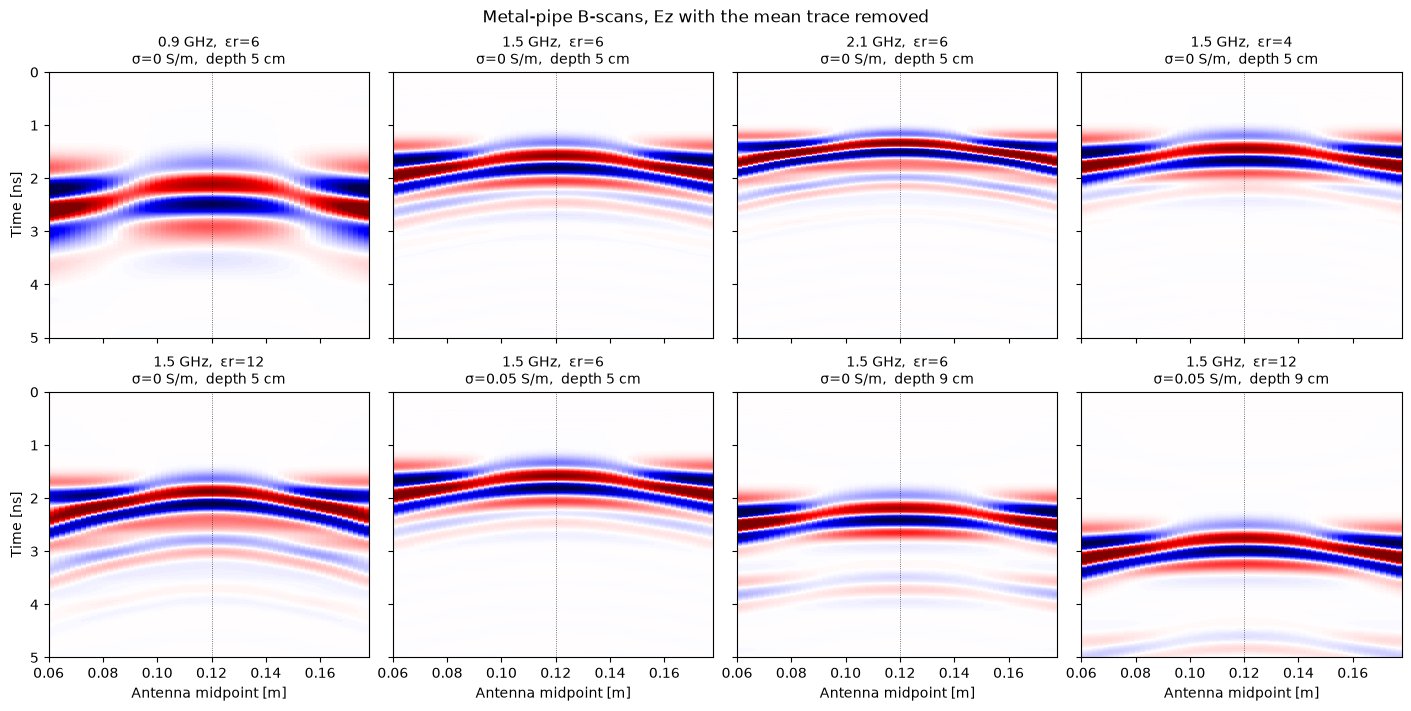

In [5]:
def read_ez(path):
    with h5py.File(path, "r") as handle:
        data = np.asarray(handle["rxs/rx1/Ez"], dtype=float)
        dt = float(handle.attrs["dt"])
    if data.ndim == 1:
        data = data[:, None]
    return data - data.mean(axis=1, keepdims=True), dt

midpoint = 0.5 * (geometry["src_x"] + geometry["rx_x"]) + geometry["step"] * np.arange(N_TRACES)
fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey=True, constrained_layout=True)
for ax, (case, path, _pipe_y, _truth) in zip(axes.ravel(), results):
    data, dt = read_ez(path)
    if data.shape[1] != N_TRACES:
        raise ValueError(f"{path.name} has {data.shape[1]} traces, expected {N_TRACES}")
    time_ns = np.arange(data.shape[0]) * dt * 1e9
    limit = np.percentile(np.abs(data), 99)
    if limit == 0:
        limit = 1
    ax.imshow(
        data,
        extent=[midpoint[0], midpoint[-1], time_ns[-1], time_ns[0]],
        aspect="auto",
        cmap="seismic",
        vmin=-limit,
        vmax=limit,
        interpolation="nearest",
    )
    ax.set_title(
        f"{case['freq'] / 1e9:.1f} GHz,  εr={case['eps']:g}\n"
        f"σ={case['sigma']:g} S/m,  depth {case['depth'] * 100:.0f} cm",
        fontsize=10,
    )
    ax.axvline(0.120, color="k", lw=0.6, ls=":", alpha=0.7)
for ax in axes[:, 0]:
    ax.set_ylabel("Time [ns]")
for ax in axes[1, :]:
    ax.set_xlabel("Antenna midpoint [m]")
fig.suptitle("Metal-pipe B-scans, Ez with the mean trace removed")
